# Extended Data Figure 3. Effects of transition turnover and directional bias on modeled TCN gain rates

In [1]:
OUTPUT_NAME="Extended_data_figure_3_turnover_bias"
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb
plt.rcParams.update(PLOT_STYLE)
OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs(OUTPUT_NAME)
MAX_PCN_TEST = 100
PRIMARY = {c.condition: c for c in standard_configurations(MAX_PCN_TEST)}

def baseline_check():
    assert np.isclose(PRIMARY["transposition off"].kappa_f, TRANSITIONS.kappa_f_off)
    assert np.isclose(PRIMARY["transposition on"].kappa_b, TRANSITIONS.kappa_b_on)
    assert np.isclose(PRIMARY["transposition on + PCN dynamics"].kappa_f, TRANSITIONS.kappa_f_pcn)
    assert CONSECUTIVE_CONVERGED_CYCLES == 8
    assert MIN_CONVERGENCE_CYCLES == 60
    assert RELAXED_DAYS_PER_CYCLE == 5 and SELECTED_DAYS_PER_CYCLE == 2
    assert np.isclose(PASSAGE_DILUTION_FACTOR, 30000)

baseline_check()
print("Core and Figure 3 configuration checks passed; mode:", RUN_MODE)
PRIMARY_SPECS=[(c.condition,float(c.kappa_f),float(c.kappa_b)) for c in standard_configurations(MAX_PCN_TEST)]
TURNOVER_LEVELS=(0.22,0.32,0.47)
BIAS_LEVELS=(-0.0225,-0.020,0.0,0.030)
GRID=[(float(S),float(D)) for S in TURNOVER_LEVELS for D in BIAS_LEVELS if S>abs(D)]

def from_turnover_bias(S,D,*,label):
    kf=(S+D)/2;kb=(S-D)/2
    assert kf>0 and kb>0
    return make_configuration(MAX_PCN_TEST,condition="transposition off",kappa_f=kf,kappa_b=kb,
                              lower_forward_rate=TRANSITIONS.lower_forward_rate,setting_label=label)
rows=[]; state_cache={}
for S,D in GRID:
    cfg=from_turnover_bias(S,D,label=f"factorial S={S:g} D={D:g}")
    assert_generator_valid(transition_matrix(MAX_PCN_TEST,cfg))
    conv=converge_periodic_state(MAX_PCN_TEST,cfg,periodic_initial_state(MAX_PCN_TEST))
    metrics=periodic_metrics(conv["TCN_low"],conv["TCN_high"],conv["minimum_daily_prepassage_density"],
                             converged=conv["converged"],population_extinct=conv["population_extinct"])
    rows.append({"family":"factorial","turnover":S,"bias":D,"kappa_f":cfg.kappa_f,"kappa_b":cfg.kappa_b,
                 "converged":bool(conv["converged"]),"cycles_to_convergence":conv["cycles_to_convergence"],
                 "TCN_low":conv["TCN_low"],"TCN_high":conv["TCN_high"],**metrics})
    if conv["converged"]:state_cache[(S,D)]=(cfg,conv["state"])

for condition,kf,kb in PRIMARY_SPECS:
    cfg=PRIMARY[condition]
    conv=converge_periodic_state(MAX_PCN_TEST,cfg,periodic_initial_state(MAX_PCN_TEST))
    metrics=periodic_metrics(conv["TCN_low"],conv["TCN_high"],conv["minimum_daily_prepassage_density"],
                             converged=conv["converged"],population_extinct=conv["population_extinct"])
    rows.append({"family":"Figure 2 control","condition":condition,"turnover":kf+kb,"bias":kf-kb,
                 "kappa_f":kf,"kappa_b":kb,"converged":bool(conv["converged"]),
                 "cycles_to_convergence":conv["cycles_to_convergence"],"TCN_low":conv["TCN_low"],
                 "TCN_high":conv["TCN_high"],**metrics})
results=pd.DataFrame(rows)
print(results[["family","turnover","bias","converged","response_valid","gain_rate"]].to_string(index=False))
assert np.allclose(results.kappa_f+results.kappa_b,results.turnover)
assert np.allclose(results.kappa_f-results.kappa_b,results.bias)


Core and Figure 3 configuration checks passed; mode: production
          family  turnover    bias  converged  response_valid  gain_rate
       factorial    0.2200 -0.0225       True            True   0.089586
       factorial    0.2200 -0.0200       True            True   0.092024
       factorial    0.2200  0.0000       True            True   0.108831
       factorial    0.2200  0.0300       True            True   0.124985
       factorial    0.3200 -0.0225       True            True   0.093036
       factorial    0.3200 -0.0200       True            True   0.095061
       factorial    0.3200  0.0000       True            True   0.109222
       factorial    0.3200  0.0300       True            True   0.123689
       factorial    0.4700 -0.0225       True            True   0.094868
       factorial    0.4700 -0.0200       True            True   0.096608
       factorial    0.4700  0.0000       True            True   0.108949
       factorial    0.4700  0.0300       True            Tru

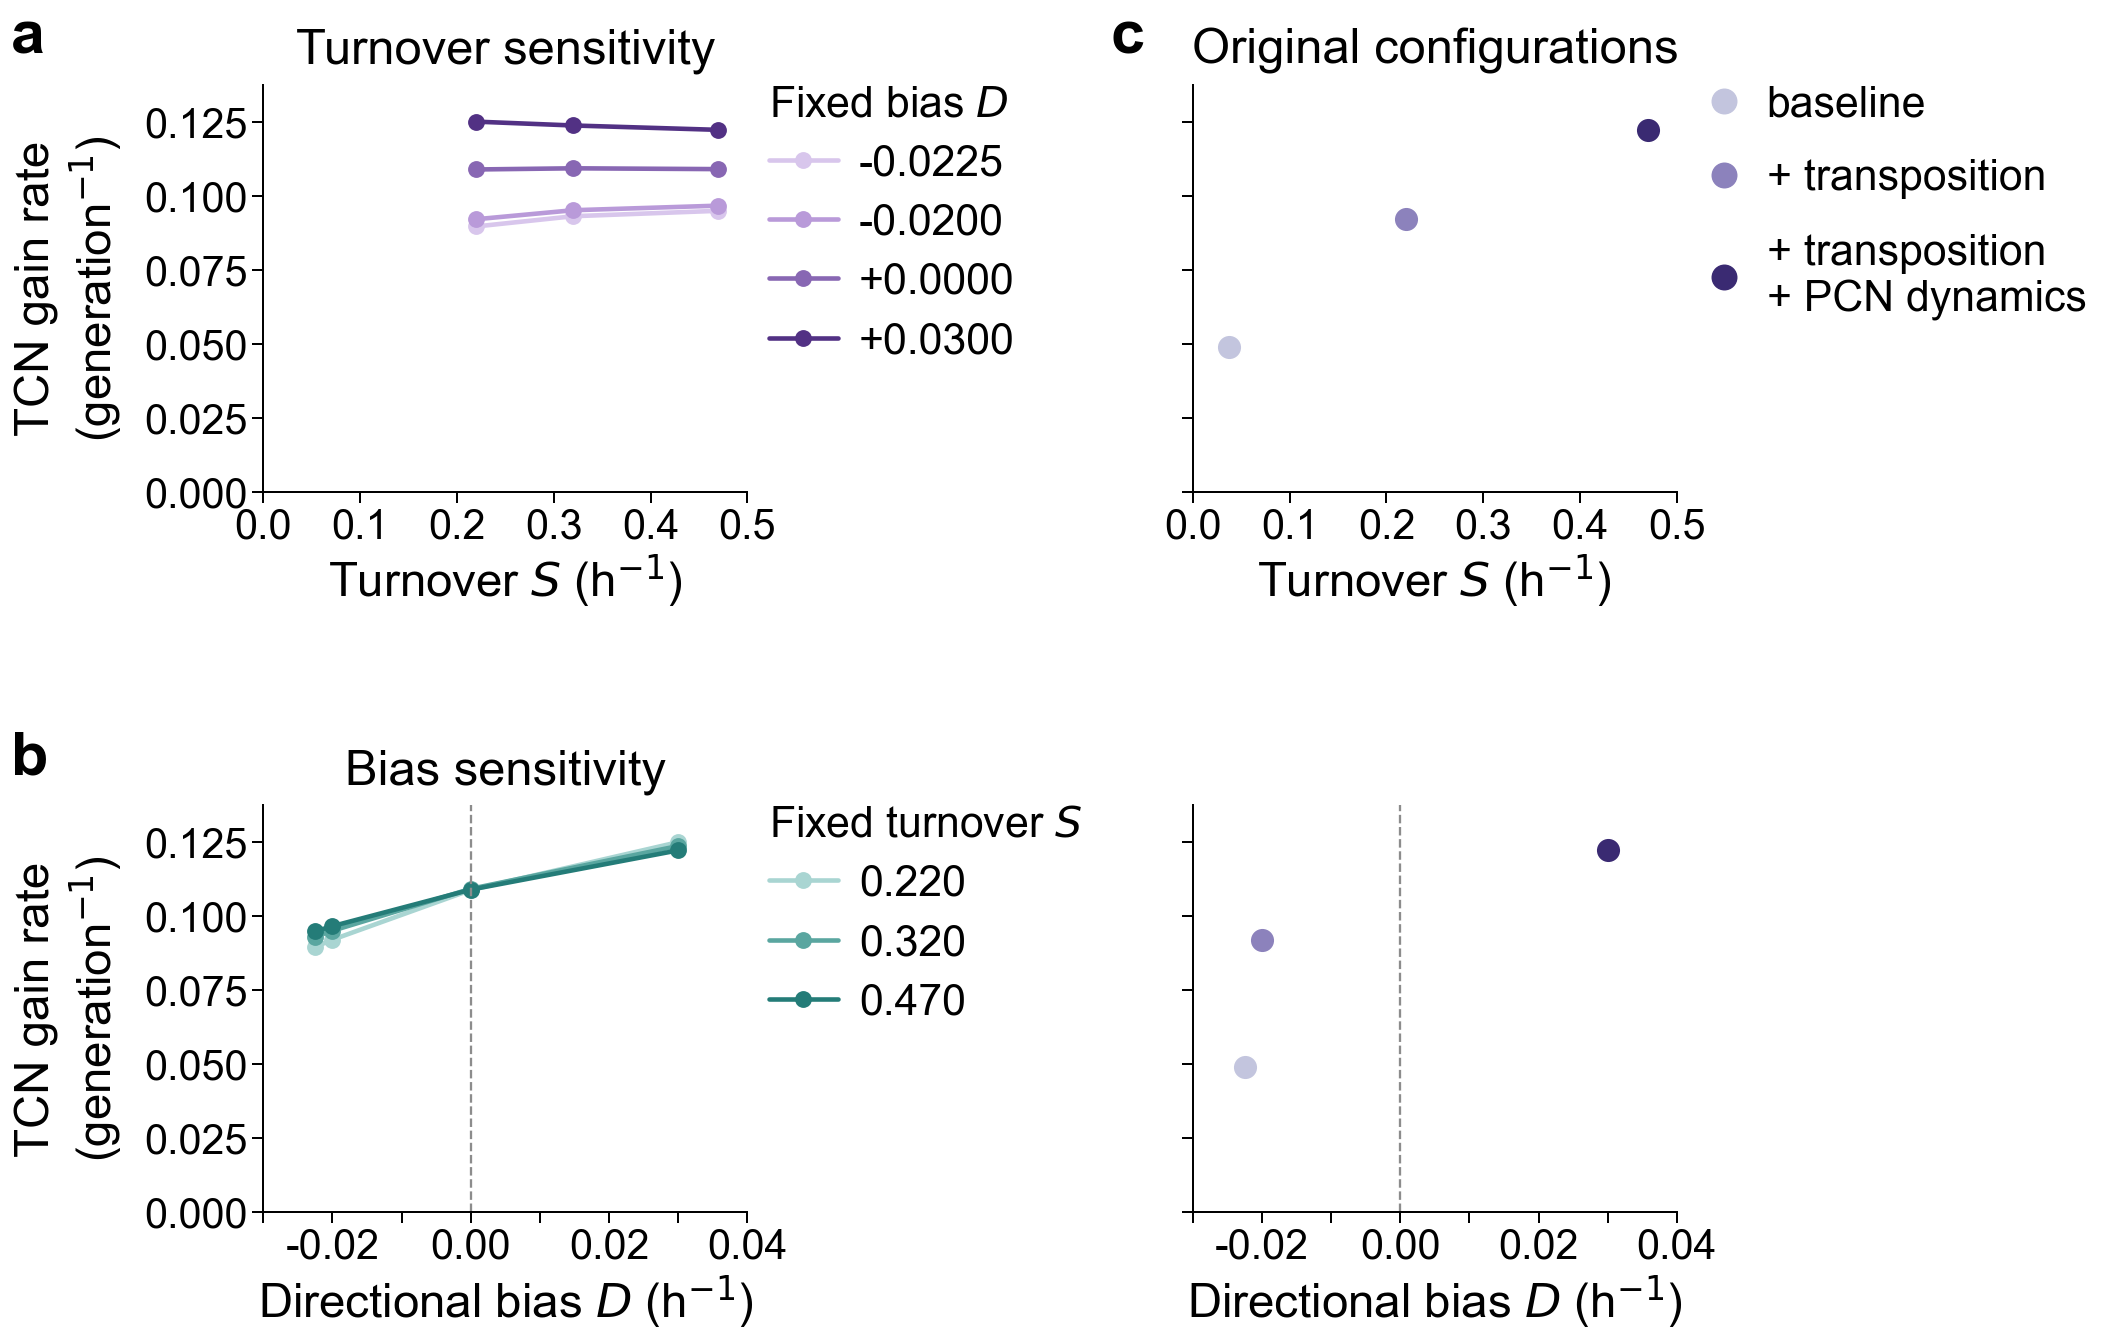

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

factorial = results.loc[(results["family"] == "factorial") & results["response_valid"]].copy()
controls = results.loc[(results["family"] == "Figure 2 control") & results["response_valid"]].copy()
assert not factorial.empty and not controls.empty

PANEL_FONT = 40
TITLE_FONT = 32
AXIS_FONT = 31
TICK_FONT = 27
LEGEND_FONT = 28

BIAS_COLORS = ["#D8C6EC", "#B99AD9", "#8867B3", "#523184"]
TURNOVER_COLORS = ["#A9D5D2", "#5AA6A0", "#247C78"]
assert len(BIAS_COLORS) >= len(BIAS_LEVELS)
assert len(TURNOVER_COLORS) >= len(TURNOVER_LEVELS)

COLS = [
    ("left_margin", 2.45),
    ("ab_plot",     4.40),
    ("ab_legend",   3.30),
    ("c_gap",       0.75),
    ("c_plot",      4.40),
    ("c_legend",    3.90),
    ("right_margin", 0.30),
]
ROWS = [
    ("top_margin",  0.15),
    ("top_title",   0.85),
    ("top_plot",    3.70),
    ("gap",         2.00),
    ("bot_title",   0.85),
    ("bot_plot",    3.70),
    ("bot_margin",  1.35),
]
C = {name: i for i, (name, _) in enumerate(COLS)}
R = {name: i for i, (name, _) in enumerate(ROWS)}

FIG_W = sum(w for _, w in COLS)
FIG_H = sum(h for _, h in ROWS)

fig = plt.figure(figsize=(FIG_W, FIG_H))
gs = fig.add_gridspec(
    len(ROWS), len(COLS),
    height_ratios=[h for _, h in ROWS],
    width_ratios=[w for _, w in COLS],
    left=0, right=1, bottom=0, top=1,
    wspace=0, hspace=0
)

def cell(row, col):
    return gs[R[row], C[col]]

def blank(row, col):
    a = fig.add_subplot(cell(row, col))
    a.axis("off")
    return a

ax_a = fig.add_subplot(cell("top_plot", "ab_plot"))
ax_b = fig.add_subplot(cell("bot_plot", "ab_plot"))
ax_c_turnover = fig.add_subplot(cell("top_plot", "c_plot"), sharex=ax_a, sharey=ax_a)
ax_c_bias = fig.add_subplot(cell("bot_plot", "c_plot"), sharex=ax_b, sharey=ax_b)

for i, D in enumerate(BIAS_LEVELS):
    d = factorial.loc[np.isclose(factorial["bias"], D)].sort_values("turnover")
    ax_a.plot(d["turnover"], d["gain_rate"], "-o", lw=3.0, ms=10,
              color=BIAS_COLORS[i], label=f"{D:+.4f}")
ax_a.set_xlabel(r"Turnover $S$ (h$^{-1}$)", fontsize=AXIS_FONT)
ax_a.set_ylabel("TCN gain rate\n(generation$^{-1}$)", fontsize=AXIS_FONT, labelpad=12)

for i, S in enumerate(TURNOVER_LEVELS):
    d = factorial.loc[np.isclose(factorial["turnover"], S)].sort_values("bias")
    ax_b.plot(d["bias"], d["gain_rate"], "-o", lw=3.0, ms=10,
              color=TURNOVER_COLORS[i], label=f"{S:.3f}")
ax_b.axvline(0, color="0.55", ls="--", lw=1.5)
ax_b.set_xlabel(r"Directional bias $D$ (h$^{-1}$)", fontsize=AXIS_FONT)
ax_b.set_ylabel("TCN gain rate\n(generation$^{-1}$)", fontsize=AXIS_FONT, labelpad=12)

control_points = []
for condition in CONDITION_ORDER:
    d = controls.loc[controls["condition"] == condition]
    assert len(d) == 1, f"Expected one valid control for {condition}, got {len(d)}"
    control_points.append((condition, float(d.iloc[0]["turnover"]),
                           float(d.iloc[0]["bias"]), float(d.iloc[0]["gain_rate"])))

for condition, S, D, gain in control_points:
    for ax, xval in ((ax_c_turnover, S), (ax_c_bias, D)):
        ax.scatter(xval, gain, s=260, color=CONDITION_COLORS[condition],
                   edgecolor="white", linewidth=1.0, zorder=4, clip_on=False)

ax_c_turnover.set_xlabel(r"Turnover $S$ (h$^{-1}$)", fontsize=AXIS_FONT)
ax_c_bias.axvline(0, color="0.55", ls="--", lw=1.5)
ax_c_bias.set_xlabel(r"Directional bias $D$ (h$^{-1}$)", fontsize=AXIS_FONT)

ax_a.set_xlim(0, 0.50)
ax_b.set_xlim(-0.03, 0.04)
valid_rates = np.concatenate([factorial["gain_rate"].to_numpy(dtype=float),
                              np.array([p[3] for p in control_points])])
common_ymax = float(np.nanmax(valid_rates)) * 1.10
ax_a.set_ylim(0, common_ymax)
ax_b.set_ylim(0, common_ymax)

ax_a.xaxis.set_major_locator(MultipleLocator(0.1))
ax_b.xaxis.set_major_locator(MultipleLocator(0.01))
ax_b.xaxis.set_major_formatter(lambda x, pos: f"{x:.2f}" if round(x / 0.01) % 2 == 0 else "")

for ax in (ax_a, ax_b, ax_c_turnover, ax_c_bias):
    ax.tick_params(axis="both", labelsize=TICK_FONT, length=7, width=1.3)
    ax.yaxis.set_major_locator(MultipleLocator(0.025))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(1.3)
for ax in (ax_c_turnover, ax_c_bias):
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelleft=False)

ax_a.set_title("Turnover sensitivity", fontsize=TITLE_FONT, pad=14)
ax_b.set_title("Bias sensitivity", fontsize=TITLE_FONT, pad=14)
ax_c_turnover.set_title("Original configurations", fontsize=TITLE_FONT, pad=14)

legend_kw = dict(loc="upper left", bbox_to_anchor=(0.06, 1.0), frameon=False,
                 fontsize=LEGEND_FONT, title_fontsize=LEGEND_FONT,
                 borderaxespad=0.0, borderpad=0.0, handletextpad=0.5,
                 labelspacing=0.45, alignment="left")

bias_handles = [Line2D([0], [0], color=BIAS_COLORS[i], lw=3.0, marker="o", ms=10,
                       label=f"{D:+.4f}") for i, D in enumerate(BIAS_LEVELS)]
turnover_handles = [Line2D([0], [0], color=TURNOVER_COLORS[i], lw=3.0, marker="o", ms=10,
                           label=f"{S:.3f}") for i, S in enumerate(TURNOVER_LEVELS)]
control_handles = [Line2D([0], [0], marker="o", linestyle="None",
                          color=CONDITION_COLORS[c], markersize=16,
                          label=DISPLAY_LABELS[c].replace(" + PCN", "\n+ PCN"))
                   for c in CONDITION_ORDER]

blank("top_plot", "ab_legend").legend(handles=bias_handles, title=r"Fixed bias $D$",
                                      handlelength=1.6, **legend_kw)
blank("bot_plot", "ab_legend").legend(handles=turnover_handles, title=r"Fixed turnover $S$",
                                      handlelength=1.6, **legend_kw)
blank("top_plot", "c_legend").legend(handles=control_handles, handlelength=1.0,
                                     **{**legend_kw, "labelspacing": 0.8})

def panel_label(row, col, letter):
    pos = cell(row, col).get_position(fig)
    fig.text(0.008, pos.y0 + pos.height / 2, letter, fontsize=PANEL_FONT,
             fontweight="bold", ha="left", va="center")

panel_label("top_title", "left_margin", "a")
panel_label("bot_title", "left_margin", "b")
c_pos = cell("top_title", "c_gap").get_position(fig)
fig.text(c_pos.x0, c_pos.y0 + c_pos.height / 2, "c", fontsize=PANEL_FONT,
         fontweight="bold", ha="left", va="center")

fig.align_ylabels([ax_a, ax_b])

save_figure(fig, "Extended_data_figure_3_turnover_bias_multipanel", FIGURE_DIR)
plt.show()